# <font color="red"> Auditoría de un Conjunto de Datos de Entrenamiento — EPS SaluCompleta (Bucaramanga) </font>
## <font color="blue"> Por Alfredo Alfredo Diaz </font>
### Taller práctico — Sesión 6: Integración DAMA y Gobernanza de Datos
### Norma de referencia: ISO/IEC 5259 (Calidad de datos para Analítica e IA/ML) e ISO/IEC 42001

**Contexto del ejercicio:** SaluCompleta es una EPS ficticia de Bucaramanga que quiere entrenar un modelo de IA para **predecir el riesgo de hospitalización** de sus afiliados. Antes de usar el dataset para entrenar el modelo, el área de Gobierno de Datos debe **auditarlo** siguiendo los criterios de la ISO/IEC 5259 y la ISO/IEC 42001.

**Su rol:** usted es el auditor de datos. Este notebook genera el dataset sintético (con defectos reales insertados a propósito) y le guía paso a paso con técnicas de EDA (Exploratory Data Analysis) para que usted **encuentre los hallazgos** y los traslade al *Informe de Hallazgos* en Word.

> Los datos son 100% sintéticos (generados con la librería `Faker`). Cualquier parecido con personas reales es coincidencia.

**No se olvide:** cada hallazgo que encuentre en este notebook debe quedar registrado en la lista de chequeo y en el informe de hallazgos del documento Word del taller.

> 🆕 **Control de versiones de datos con DVC:** el dataset recibido (v1) se registra como **evidencia inmutable** con *DVC (Data Version Control)* antes de auditarlo; después el equipo de datos entrega una versión remediada (v2) y usted audita la **trazabilidad** entre versiones. Vea las secciones **0.1, 1.1, 10 y 11**.


## 0. Preparación del entorno

In [1]:
!pip install faker --quiet
import numpy as np
import pandas as pd
from faker import Faker
import random
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', 100)
sns.set_theme(style="whitegrid")
print("Librerías listas ✅")


Librerías listas ✅


## 0.1 Prerrequisitos de versionado de datos (Git + DVC)

Para que un dataset de entrenamiento sea **trazable** (ISO/IEC 42001) hay que poder responder: *¿qué versión exacta de los datos se usó?, ¿quién la cambió, cuándo y por qué?, ¿sigue siendo hoy la misma?* **DVC** responde estas preguntas trabajando junto a **Git**:

| Herramienta | Qué guarda |
|---|---|
| **Git** | El código, los scripts y unos archivos de texto diminutos con extensión `.dvc` (punteros con el hash MD5, el tamaño y el nombre del dato). **No guarda los datos.** |
| **DVC** | Los datos en una *caché* local y en un *almacén remoto* (carpeta compartida, S3, Azure, Google Drive, SSH…), identificados por su hash. |

**Antes de ejecutar este cuaderno en VS Code:**

1. Instale **Git** desde https://git-scm.com/downloads y verifique en una terminal: `git --version`.
2. Cree una **carpeta propia** para el taller (por ejemplo `taller_gobernanza_datos`), copie allí este cuaderno y ábrala con *Archivo → Abrir carpeta*. **No** la cree dentro de otro repositorio Git.
3. Seleccione un kernel de Python donde pueda instalar paquetes, de preferencia un entorno virtual (*Select Kernel → Python Environments…*).
4. Ejecute la celda siguiente: instala DVC, define la función `run()` (para ejecutar comandos de Git y DVC desde el cuaderno) y muestra las versiones.


In [2]:
%pip install dvc --quiet

import os, re, sys, subprocess

# Hace que 'git', 'dvc' y 'python' se resuelvan con el entorno del kernel de VS Code
_bin = os.path.dirname(sys.executable)
_ENV = os.environ.copy()
_ENV["PATH"] = os.pathsep.join([_bin, os.path.join(_bin, "Scripts"), _ENV.get("PATH", "")])
_ENV["PYTHONIOENCODING"] = "utf-8"
_ENV["DVC_NO_ANALYTICS"] = "1"   # sin telemetría

def run(cmd, devolver=False):
    """Ejecuta un comando de terminal (git / dvc) desde el cuaderno y muestra su salida."""
    original = cmd
    if cmd.startswith("dvc "):   # usa el mismo Python del kernel (evita problemas de PATH en Windows)
        cmd = f'"{sys.executable}" -m dvc ' + cmd[4:]
    print(f"$ {original}")
    r = subprocess.run(cmd, shell=True, capture_output=True, text=True,
                       encoding="utf-8", errors="replace", env=_ENV)
    salida = re.sub(r"\x1b\[[0-9;?]*[A-Za-z]", "", r.stdout + r.stderr)          # quita códigos de color/cursor
    lineas = [l for l in salida.splitlines() if not (l and "\u2800" <= l[0] <= "\u28ff")]  # quita la animación de progreso de DVC
    salida = "\n".join(lineas).strip()
    print(salida if salida else "(sin salida)")
    if r.returncode != 0:
        print(f"[código de salida: {r.returncode}]")
    print()
    return r if devolver else None

print("Python del kernel:", sys.executable)
print("Carpeta de trabajo:", os.getcwd(), "\n")
run("git --version")
run("dvc --version")


Note: you may need to restart the kernel to use updated packages.
Python del kernel: d:\Users\adiaz\Documents\GitHub\taller_gobernanza_datos\.venv\Scripts\python.exe
Carpeta de trabajo: d:\Users\adiaz\Documents\GitHub\taller_gobernanza_datos 

$ git --version
git version 2.53.0.windows.1

$ dvc --version
3.67.1



## 1. Generación del dataset sintético
Ejecute la celda siguiente para generar el dataset **`pacientes_salucompleta_v1.csv`**.

Este dataset simula el ejercicio real de un equipo de datos que entrega un dataset a un auditor **sin haberlo limpiado ni validado**. Contiene, a propósito, varios de los problemas típicos que la ISO/IEC 5259 pide evaluar: datos personales sin proteger, variables protegidas sin justificación técnica, desbalance de clases, outliers, nulos, columnas redundantes, formatos inconsistentes y duplicados.

No modifique el `seed` para que sus resultados sean reproducibles y comparables con los de sus compañeros.


In [3]:
random.seed(42)
np.random.seed(42)
fake = Faker('es_CO')
Faker.seed(42)

N = 1200  # se generan de más porque luego se agregan duplicados

# ---- Catálogos de valores ----
genero_formatos = ['M', 'F', 'Masculino', 'Femenino', 'masculino', 'femenino', 'Otro', np.nan]
genero_pesos    = [0.30, 0.30, 0.15, 0.15, 0.03, 0.03, 0.02, 0.02]

# Etnia: grupo minoritario deliberadamente subrepresentado (rompe representatividad)
etnia_valores = ['Mestizo', 'Blanco', 'Afrodescendiente', 'Indigena', 'ROM', np.nan]
etnia_pesos   = [0.60, 0.30, 0.055, 0.02, 0.005, 0.02]

religion_valores     = ['Catolica', 'Cristiana', 'Ninguna', 'Otra', np.nan]
orientacion_valores  = ['Heterosexual', 'Homosexual', 'Bisexual', 'Prefiere no decir', np.nan]
politica_valores     = ['Liberal', 'Conservador', 'Independiente', 'Ninguno', np.nan]

estrato_valores       = [1, 2, 3, 4, 5, 6]
nivel_edu_valores     = ['Ninguno', 'Primaria', 'Secundaria', 'Tecnico', 'Universitario', 'Posgrado']
estado_civil_valores  = ['Soltero', 'Casado', 'Union libre', 'Divorciado', 'Viudo']
municipios            = ['Bucaramanga', 'Floridablanca', 'Giron', 'Piedecuesta']
tipo_afiliacion_valores = ['Contributivo', 'Subsidiado']

colores_cabello  = ['Negro', 'Castaño', 'Rubio', 'Canoso', 'Rojo']
marcas_celular   = ['Samsung', 'iPhone', 'Xiaomi', 'Motorola', 'Huawei']
redes_sociales   = ['Facebook', 'Instagram', 'TikTok', 'WhatsApp', 'Ninguna']
equipos_futbol   = ['Atl. Bucaramanga', 'Santa Fe', 'Millonarios', 'Nacional', 'Ninguno']

diagnosticos = ['I10 - Hipertension esencial', 'E11 - Diabetes mellitus tipo 2',
                'J45 - Asma', 'N18 - Enfermedad renal cronica', 'I25 - Cardiopatia isquemica',
                'K21 - Enfermedad por reflujo', 'F32 - Episodio depresivo', 'Z00 - Examen general']

rows = []
for i in range(N):
    edad = int(np.clip(np.random.normal(45, 18), 0, 95))
    nacimiento = fake.date_of_birth(minimum_age=max(edad - 1, 0), maximum_age=edad + 1)

    peso  = float(np.clip(np.random.normal(70, 15), 35, 140))
    talla = float(np.clip(np.random.normal(1.65, 0.1), 1.4, 2.0))
    imc   = round(peso / (talla ** 2), 1)

    row = {
        "id_paciente": f"PAC-{str(i+1).zfill(5)}",
        "nombre_completo": fake.name(),
        "numero_documento": fake.unique.random_number(digits=10, fix_len=True),
        "direccion_residencia": fake.address().replace("\\n", ", "),
        "telefono_contacto": fake.phone_number(),
        "correo_electronico": fake.email(),
        "fecha_nacimiento": nacimiento.isoformat(),
        "edad": edad,  # redundante con fecha_nacimiento
        "genero": random.choices(genero_formatos, weights=genero_pesos, k=1)[0],
        "estrato_socioeconomico": random.choice(estrato_valores),
        "nivel_educativo": random.choice(nivel_edu_valores),
        "estado_civil": random.choice(estado_civil_valores),
        "municipio_residencia": random.choice(municipios),
        "etnia": random.choices(etnia_valores, weights=etnia_pesos, k=1)[0],
        "religion": random.choice(religion_valores),
        "orientacion_sexual": random.choice(orientacion_valores),
        "afiliacion_politica": random.choice(politica_valores),
        "tipo_afiliacion_eps": random.choice(tipo_afiliacion_valores),
        "eps_anterior": random.choice(['Nueva EPS', 'Sanitas', 'Sura', 'Ninguna', np.nan]),
        "eps_anterior_afiliacion": None,  # duplicado exacto de eps_anterior
        "color_cabello": random.choice(colores_cabello),
        "marca_celular": random.choice(marcas_celular),
        "red_social_favorita": random.choice(redes_sociales),
        "equipo_futbol_favorito": random.choice(equipos_futbol),
        "diagnostico_principal": random.choice(diagnosticos),
        "presion_sistolica": int(np.clip(np.random.normal(125, 18), 80, 200)),
        "presion_diastolica": int(np.clip(np.random.normal(80, 12), 50, 130)),
        "frecuencia_cardiaca": int(np.clip(np.random.normal(78, 12), 45, 160)),
        "peso_kg": round(peso, 1),
        "talla_m": round(talla, 2),
        "imc": imc,  # redundante, derivable de peso/talla
        "glucosa_mg_dl": round(float(np.clip(np.random.normal(100, 30), 50, 400)), 1),
        "colesterol_total": round(float(np.clip(np.random.normal(190, 35), 100, 350)), 1),
        "numero_consultas_ultimo_anio": np.random.poisson(3),
        "numero_hospitalizaciones_previas": np.random.poisson(0.4),
        "dias_estancia_hospitalaria": np.random.poisson(2),
        "fecha_ultima_consulta": None,
        "medico_tratante": fake.name(),
        "hospitalizado": None,
    }
    row["eps_anterior_afiliacion"] = row["eps_anterior"]
    rows.append(row)

df = pd.DataFrame(rows)

# ---- Target desbalanceado ----
df["hospitalizado"] = np.random.choice(["No", "Si"], size=N, p=[0.88, 0.12])

# ---- Fechas con formatos inconsistentes ----
def fecha_random_formato():
    d = fake.date_between(start_date='-1y', end_date='today')
    fmt = random.choice(["%Y-%m-%d", "%d/%m/%Y", "%d-%m-%Y", "%B %d, %Y"])
    return d.strftime(fmt)

df["fecha_ultima_consulta"] = [fecha_random_formato() for _ in range(N)]

# ---- Outliers deliberados ----
outlier_idx = np.random.choice(N, size=25, replace=False)
for idx in outlier_idx[:8]:
    df.loc[idx, "edad"] = random.choice([-5, 180, 250])
for idx in outlier_idx[8:15]:
    df.loc[idx, "peso_kg"] = random.choice([-70, 500, 0])
for idx in outlier_idx[15:20]:
    df.loc[idx, "presion_sistolica"] = random.choice([500, -20, 999])
for idx in outlier_idx[20:25]:
    df.loc[idx, "dias_estancia_hospitalaria"] = random.choice([365, 900])

# ---- Nulos deliberados en columnas clínicas clave ----
for col, frac in [("glucosa_mg_dl", 0.12), ("colesterol_total", 0.10),
                   ("presion_diastolica", 0.06), ("numero_consultas_ultimo_anio", 0.05),
                   ("talla_m", 0.04)]:
    null_idx = np.random.choice(N, size=int(N * frac), replace=False)
    df.loc[null_idx, col] = np.nan

# ---- Duplicados exactos y casi-duplicados ----
dup_exact = df.sample(15, random_state=1)
dup_near = df.sample(10, random_state=2).copy()
dup_near["numero_consultas_ultimo_anio"] = dup_near["numero_consultas_ultimo_anio"] + 1
df = pd.concat([df, dup_exact, dup_near], ignore_index=True)

df = df.sample(frac=1, random_state=7).reset_index(drop=True)
df = df.iloc[:1150].reset_index(drop=True)

df.to_csv("pacientes_salucompleta_v1.csv", index=False)
print(f"Dataset generado: {df.shape[0]} registros, {df.shape[1]} columnas")
df.head()


Dataset generado: 1150 registros, 39 columnas


,id_paciente,nombre_completo,numero_documento,direccion_residencia,telefono_contacto,correo_electronico,fecha_nacimiento,edad,genero,estrato_socioeconomico,nivel_educativo,estado_civil,municipio_residencia,etnia,religion,orientacion_sexual,afiliacion_politica,tipo_afiliacion_eps,eps_anterior,eps_anterior_afiliacion,color_cabello,marca_celular,red_social_favorita,equipo_futbol_favorito,diagnostico_principal,presion_sistolica,presion_diastolica,frecuencia_cardiaca,peso_kg,talla_m,imc,glucosa_mg_dl,colesterol_total,numero_consultas_ultimo_anio,numero_hospitalizaciones_previas,dias_estancia_hospitalaria,fecha_ultima_consulta,medico_tratante,hospitalizado
0,PAC-00052,Elena Muñoz Valencia,2593765711,Dg. 154 # 23A-83\nTorre 1 apartamento 59\n9139...,(+57)3063854678,natalia58@example.com,1999-03-19,28,M,2,Secundaria,Union libre,Piedecuesta,Mestizo,Cristiana,Bisexual,NaN,Contributivo,Ninguna,Ninguna,Negro,Huawei,Instagram,Santa Fe,I25 - Cardiopatia isquemica,143,68.0,109,49.7,1.55,20.6,114.8,196.5,2.0,0,1,18-05-2026,Luis Nel Correa Villa,No
1,PAC-00523,Alfonso Alfonso Valencia Sierra,4549582675,"Avenida carrera 5ª # 22-8\n546055\nEl Zulia, N...",+57 308 618 67 06,drojas@example.org,1970-01-07,57,F,6,Universitario,Casado,Floridablanca,Mestizo,Otra,Prefiere no decir,Ninguno,Contributivo,Sura,Sura,Negro,Huawei,Ninguna,Nacional,F32 - Episodio depresivo,151,NaN,96,55.5,1.63,21.0,89.9,150.8,2.0,0,2,07-11-2025,Alonso Escobar Burgos,No
2,PAC-00180,Janeth Tatiana Rodríguez Navarro,3284318901,Calle 68 # 2-21 Este\nEtapa 4 apartamento 416\...,3042241246,luzsalamanca@example.org,1974-01-22,53,F,2,Primaria,Union libre,Piedecuesta,Blanco,Ninguna,Heterosexual,Ninguno,Contributivo,Sanitas,Sanitas,Canoso,Huawei,Ninguna,Nacional,F32 - Episodio depresivo,139,81.0,94,91.8,1.72,31.0,112.3,159.9,3.0,1,6,12/03/2026,Edith Jiménez,No
3,PAC-01174,Mauricio Mesa,5757795568,"Cl. 85 # 5-61\n526514\nGuaitarilla, Nariño",+573128886465,loaizadavid@example.org,1979-01-28,250,F,1,Primaria,Soltero,Piedecuesta,Blanco,Ninguna,Heterosexual,Liberal,Subsidiado,Sura,Sura,Rojo,Xiaomi,WhatsApp,Millonarios,N18 - Enfermedad renal cronica,145,NaN,80,81.1,1.80,25.0,NaN,197.5,4.0,1,1,2026-05-24,David García,No
4,PAC-00938,Alfredo Geovanny Romero Bautista,4659550214,Carrera 127 Sur # 4Q-85 Este\nOficina 8\n66815...,01 8002 149 241,elsyacosta@example.org,1992-12-25,32,M,6,Ninguno,Divorciado,Giron,Blanco,Cristiana,Prefiere no decir,Conservador,Subsidiado,NaN,NaN,Castaño,Motorola,TikTok,Ninguno,I10 - Hipertension esencial,134,NaN,78,67.5,1.85,19.8,180.9,156.8,3.0,0,5,2026-07-19,Santiago Ospina Salcedo,No


## 1.1 Congelar la evidencia: registrar la versión v1 con DVC

Un auditor **no audita sobre un archivo que cualquiera pueda modificar**. Antes de explorar el dataset se "congela" tal como fue recibido: DVC calcula su huella digital (hash MD5), lo guarda en la caché y en un almacén remoto, y Git registra el puntero con fecha y autor. Cualquier cambio posterior será detectable.

**Paso 1 — Inicializar Git y DVC en la carpeta del taller (una sola vez).** Edite su nombre y correo: se guardan solo en este repositorio y quedan en cada *commit* como evidencia de autoría.


In [4]:
AUDITOR_NOMBRE = "Nombre Apellido"        # <-- edite
AUDITOR_CORREO = "auditor@ejemplo.com"    # <-- edite

# Git: repositorio local + identidad del auditor
run("git init")
run(f'git config user.name "{AUDITOR_NOMBRE}"')
run(f'git config user.email "{AUDITOR_CORREO}"')

# DVC: inicializar (solo si aún no existe) y desactivar la telemetría
if not os.path.exists(".dvc/config"):
    run("dvc init")
run("dvc config core.analytics false")

# Almacén remoto. Aquí es una carpeta junto al proyecto; en producción sería S3, Azure o SSH
# con cifrado y control de acceso por rol.
run("dvc remote add -d --force almacen_taller ../almacen_dvc_salucompleta")
run("git status --short")


$ git init
Reinitialized existing Git repository in D:/Users/adiaz/Documents/GitHub/taller_gobernanza_datos/.git/

$ git config user.name "Nombre Apellido"
(sin salida)

$ git config user.email "auditor@ejemplo.com"
(sin salida)

$ dvc config core.analytics false
(sin salida)

$ dvc remote add -d --force almacen_taller ../almacen_dvc_salucompleta
Setting 'almacen_taller' as a default remote.

$ git status --short
?? Auditoria_Dataset_SaluCompleta_ISO5259.ipynb
?? requirements.txt



**Paso 2 — Registrar el dataset v1.** `dvc add` calcula el hash, guarda el dato en la caché y crea el puntero `pacientes_salucompleta_v1.csv.dvc`. Luego se confirma el puntero en Git, se etiqueta la versión y se respalda el dato con `dvc push`.

> Si ejecuta esta celda por segunda vez verá mensajes como *nothing to commit* o *tag already exists*: es normal, la versión ya estaba registrada.


In [5]:
ARCHIVO_V1 = "pacientes_salucompleta_v1.csv"

run(f"dvc add {ARCHIVO_V1}")     # calcula el hash, mueve el dato a la caché y crea el puntero .dvc
run(f"git add {ARCHIVO_V1}.dvc .gitignore .dvc/config")
run('git commit -m "Linea base: dataset crudo v1 recibido del equipo de datos (sin limpiar ni validar)"')
run('git tag -a v1.0-crudo -m "Version v1 tal como fue recibida, antes de la auditoria"')
run("dvc push")                  # copia el dato al almacén remoto

print("Contenido del puntero (esto es lo que Git guarda, NO los datos):\n")
print(open(f"{ARCHIVO_V1}.dvc").read())


$ dvc add pacientes_salucompleta_v1.csv
To track the changes with git, run:

	git add pacientes_salucompleta_v1.csv.dvc

To enable auto staging, run:

	dvc config core.autostage true

$ git add pacientes_salucompleta_v1.csv.dvc .gitignore .dvc/config
(sin salida)

$ git commit -m "Linea base: dataset crudo v1 recibido del equipo de datos (sin limpiar ni validar)"
On branch master
Untracked files:
  (use "git add <file>..." to include in what will be committed)
	Auditoria_Dataset_SaluCompleta_ISO5259.ipynb
	requirements.txt

nothing added to commit but untracked files present (use "git add" to track)
[código de salida: 1]

$ git tag -a v1.0-crudo -m "Version v1 tal como fue recibida, antes de la auditoria"
fatal: tag 'v1.0-crudo' already exists
[código de salida: 128]

$ dvc push
Everything is up to date.

Contenido del puntero (esto es lo que Git guarda, NO los datos):

outs:
- md5: 99b747635a2ebb187d7bd9d69e583e0f
  size: 449015
  hash: md5
  path: pacientes_salucompleta_v1.csv



**Registre en la lista de chequeo (sección de trazabilidad/versionado):** el hash `md5` y el tamaño de v1 (campos del archivo `.dvc`), la fecha y el autor del *commit*, la etiqueta `v1.0-crudo` y que el dato quedó respaldado en el almacén remoto.


## 2. Carga y exploración inicial
Esta es la fase de **reconocimiento** antes de auditar: entender qué contiene el dataset, cuántos registros y variables tiene, y qué tipo de dato hay en cada columna.


In [6]:
df = pd.read_csv("pacientes_salucompleta_v1.csv")
print("Dimensiones:", df.shape)
df.info()


Dimensiones: (1150, 39)
<class 'pandas.DataFrame'>
RangeIndex: 1150 entries, 0 to 1149
Data columns (total 39 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   id_paciente                       1150 non-null   str    
 1   nombre_completo                   1150 non-null   str    
 2   numero_documento                  1150 non-null   int64  
 3   direccion_residencia              1150 non-null   str    
 4   telefono_contacto                 1150 non-null   str    
 5   correo_electronico                1150 non-null   str    
 6   fecha_nacimiento                  1150 non-null   str    
 7   edad                              1150 non-null   int64  
 8   genero                            1133 non-null   str    
 9   estrato_socioeconomico            1150 non-null   int64  
 10  nivel_educativo                   1150 non-null   str    
 11  estado_civil                      1150 non-null   str   

In [7]:
df.describe(include='all').T


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id_paciente,1150,1130,PAC-00684,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
nombre_completo,1150,1129,Marina Amparo Burgos,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
numero_documento,1150.0,NaN,NaN,NaN,5457454086.143478,2626260314.520562,1002756157.0,3134892740.75,5425906816.0,7759045014.25,9989495548.0
direccion_residencia,1150,1130,"Cl. 67 # 30-30\n251896\nTibacuy, Cundinamarca",3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
telefono_contacto,1150,1130,576088234056,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
correo_electronico,1150,1124,diazana@example.com,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
fecha_nacimiento,1150,1109,1975-11-29,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
edad,1150.0,NaN,NaN,NaN,45.114783,21.192081,-5.0,32.0,45.0,57.0,250.0
genero,1133,7,M,360,NaN,NaN,NaN,NaN,NaN,NaN,NaN
estrato_socioeconomico,1150.0,NaN,NaN,NaN,3.548696,1.693887,1.0,2.0,4.0,5.0,6.0


## 3. Auditoría de **Pertinencia** (ISO/IEC 5259 · ISO/IEC 42001)
> ¿Los datos son adecuados y necesarios para el problema técnico (predecir hospitalización)?

Un dato puede ser de excelente calidad técnica y **aun así no ser pertinente** si no aporta valor al problema o si es una variable protegida que introduce riesgo legal/ético sin justificación técnica.

**Tarea del auditor:** identifique dos grupos de columnas:
1. **Variables protegidas / sensibles** que no tienen justificación técnica para estar en un modelo de predicción clínica.
2. **Variables irrelevantes** (ruido) que no tienen relación causal ni estadística razonable con el desenlace clínico.


In [8]:
columnas = df.columns.tolist()
print(f"Total de columnas en el dataset: {len(columnas)}\n")
for c in columnas:
    print("-", c)


Total de columnas en el dataset: 39

- id_paciente
- nombre_completo
- numero_documento
- direccion_residencia
- telefono_contacto
- correo_electronico
- fecha_nacimiento
- edad
- genero
- estrato_socioeconomico
- nivel_educativo
- estado_civil
- municipio_residencia
- etnia
- religion
- orientacion_sexual
- afiliacion_politica
- tipo_afiliacion_eps
- eps_anterior
- eps_anterior_afiliacion
- color_cabello
- marca_celular
- red_social_favorita
- equipo_futbol_favorito
- diagnostico_principal
- presion_sistolica
- presion_diastolica
- frecuencia_cardiaca
- peso_kg
- talla_m
- imc
- glucosa_mg_dl
- colesterol_total
- numero_consultas_ultimo_anio
- numero_hospitalizaciones_previas
- dias_estancia_hospitalaria
- fecha_ultima_consulta
- medico_tratante
- hospitalizado


**Pista 1 — Variables protegidas.** La ISO/IEC 42001 y el marco de no discriminación algorítmica piden identificar variables de categoría especial (etnia, religión, orientación sexual, afiliación política, etc.). Revise si estas variables existen en el dataset y si el equipo que lo entregó documentó una justificación técnica para incluirlas.


In [9]:
posibles_variables_protegidas = ["etnia", "religion", "orientacion_sexual", "afiliacion_politica"]
presentes = [c for c in posibles_variables_protegidas if c in df.columns]
print("Variables protegidas encontradas en el dataset:", presentes)
df[presentes].isna().mean().rename("% nulos").to_frame()


Variables protegidas encontradas en el dataset: ['etnia', 'religion', 'orientacion_sexual', 'afiliacion_politica']


,% nulos
etnia,0.018261
religion,0.191304
orientacion_sexual,0.187826
afiliacion_politica,0.210435


**Pista 2 — Variables irrelevantes (ruido).** Compare estas columnas con el objetivo del modelo (predecir `hospitalizado`). ¿Aporta algo clínico o de gestión de riesgo saber la marca de celular o el equipo de fútbol favorito del paciente?


In [11]:
posibles_irrelevantes = ["color_cabello", "marca_celular", "red_social_favorita", "equipo_futbol_favorito"]
for col in posibles_irrelevantes:
    print(f"\n--- {col} ---")
    print(df[col].value_counts(dropna=False))



--- color_cabello ---
color_cabello
Rojo       248
Negro      232
Rubio      228
Canoso     223
Castaño    219
Name: count, dtype: int64

--- marca_celular ---
marca_celular
Samsung     236
Motorola    234
iPhone      233
Huawei      228
Xiaomi      219
Name: count, dtype: int64

--- red_social_favorita ---
red_social_favorita
Ninguna      241
WhatsApp     234
Instagram    233
Facebook     228
TikTok       214
Name: count, dtype: int64

--- equipo_futbol_favorito ---
equipo_futbol_favorito
Atl. Bucaramanga    254
Millonarios         253
Nacional            217
Santa Fe            216
Ninguno             210
Name: count, dtype: int64


✏️ **Registre en la lista de chequeo (sección de Pertinencia):** cuáles variables protegidas encontró, cuáles variables irrelevantes encontró, y si el dataset trae una ficha de justificación técnica para cada una (spoiler: no la trae).


## 4. Auditoría de **Representatividad** (ISO/IEC 5259)
> ¿El dataset refleja la diversidad real de la población para evitar sesgos discriminatorios?

Aquí se busca **desbalance de clases** (en la variable objetivo) y **desbalance en subgrupos poblacionales** (por ejemplo, grupos étnicos o género) que puedan generar que el modelo discrimine sistemáticamente a las minorías por falta de datos suficientes para aprender su comportamiento.


Distribución de la variable objetivo 'hospitalizado':
hospitalizado
No    86.9
Si    13.1
Name: proportion, dtype: float64


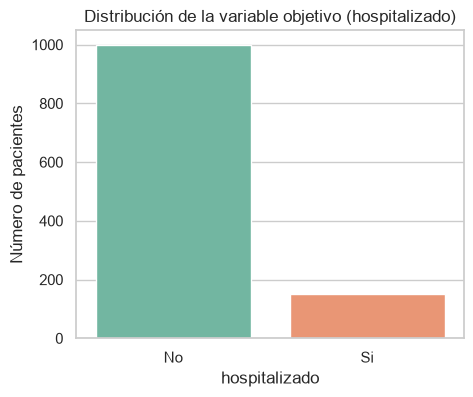

In [13]:
print("Distribución de la variable objetivo 'hospitalizado':")
print(df["hospitalizado"].value_counts(normalize=True).round(3) * 100)

plt.figure(figsize=(5,4))
sns.countplot(data=df, x="hospitalizado", hue="hospitalizado", palette="Set2", legend=False)
plt.title("Distribución de la variable objetivo (hospitalizado)")
plt.ylabel("Número de pacientes")
plt.show()


Distribución de 'etnia':
etnia
Mestizo             60.1
Blanco              31.0
Afrodescendiente     4.3
Indigena             2.2
NaN                  1.8
ROM                  0.6
Name: proportion, dtype: float64


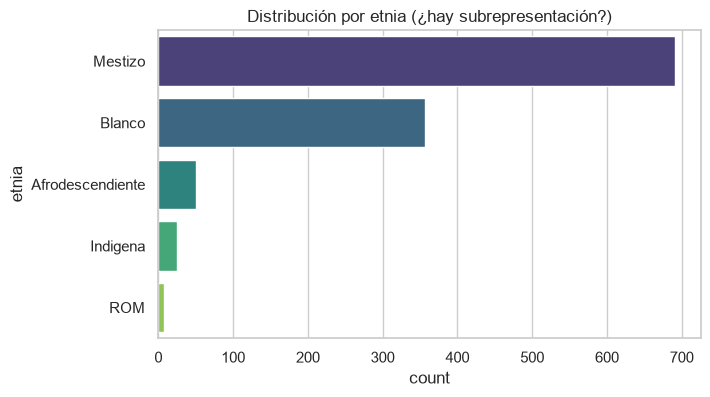

In [14]:
print("Distribución de 'etnia':")
print(df["etnia"].value_counts(normalize=True, dropna=False).round(3) * 100)

plt.figure(figsize=(7,4))
sns.countplot(data=df, y="etnia", order=df["etnia"].value_counts().index, hue="etnia", palette="viridis", legend=False)
plt.title("Distribución por etnia (¿hay subrepresentación?)")
plt.show()


In [15]:
tabla_cruzada = pd.crosstab(df["etnia"], df["hospitalizado"], normalize="index").round(3) * 100
print("Tasa de hospitalización (%) por grupo étnico:")
tabla_cruzada


Tasa de hospitalización (%) por grupo étnico:


hospitalizado,No,Si
etnia,,
Afrodescendiente,80.0,20.0
Blanco,87.4,12.6
Indigena,100.0,0.0
Mestizo,87.1,12.9
ROM,42.9,57.1


 **Registre en la lista de chequeo (sección de Representatividad):** ¿qué grupo(s) están subrepresentados? ¿el desbalance del target podría hacer que el modelo casi nunca prediga "Sí hospitalizado"? ¿hay suficientes registros por subgrupo étnico para que el modelo aprenda su patrón de riesgo de forma confiable?


## 5. Auditoría de **Integridad** (ISO/IEC 5259)
> ¿Los datos están libres de errores sustanciales que puedan distorsionar la inferencia del modelo? (outliers, formatos inconsistentes, duplicados)


### 5.1 Valores atípicos (outliers)

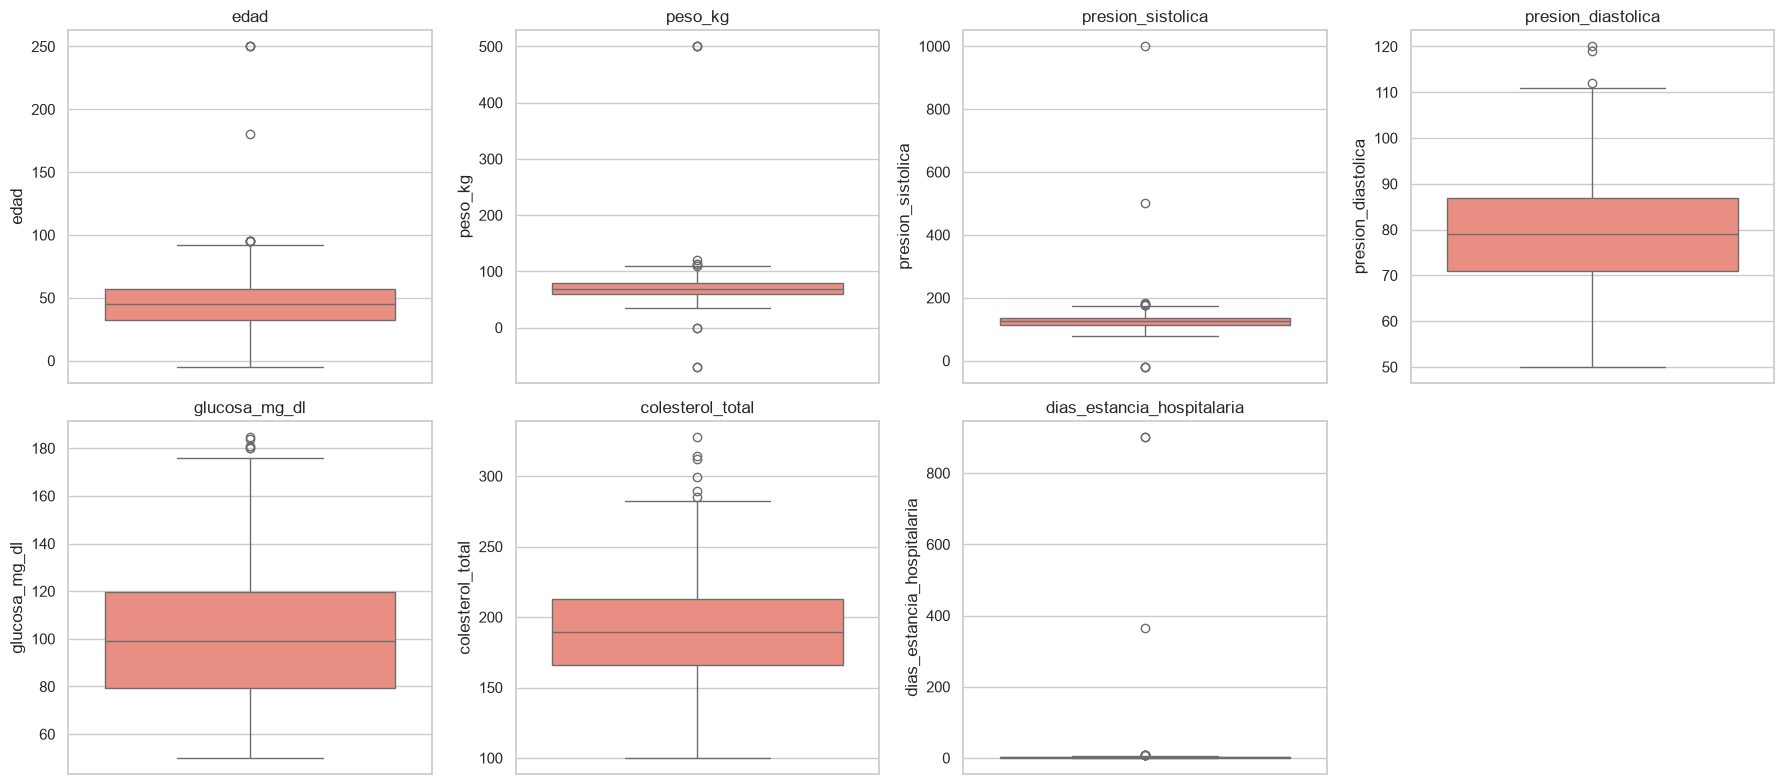

In [16]:
num_cols = ["edad", "peso_kg", "presion_sistolica", "presion_diastolica",
            "glucosa_mg_dl", "colesterol_total", "dias_estancia_hospitalaria"]

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()
for i, col in enumerate(num_cols):
    sns.boxplot(y=df[col], ax=axes[i], color="salmon")
    axes[i].set_title(col)
fig.delaxes(axes[-1])
plt.tight_layout()
plt.show()


In [17]:
def resumen_outliers_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    atipicos = serie[(serie < lim_inf) | (serie > lim_sup)]
    return len(atipicos), lim_inf, lim_sup

print(f"{'Variable':30s} {'N° atípicos':>12s} {'Límite inferior':>18s} {'Límite superior':>18s}")
for col in num_cols:
    n, li, ls = resumen_outliers_iqr(df[col].dropna())
    print(f"{col:30s} {n:12d} {li:18.1f} {ls:18.1f}")


Variable                        N° atípicos    Límite inferior    Límite superior
edad                                      9               -5.5               94.5
peso_kg                                  11               28.9              109.6
presion_sistolica                        10               77.0              173.0
presion_diastolica                        3               47.0              111.0
glucosa_mg_dl                             5               19.5              179.5
colesterol_total                          6               95.1              283.2
dias_estancia_hospitalaria                9               -2.0                6.0


Revise también valores **clínicamente imposibles** (una edad negativa o de 250 años, una presión sistólica de 999, un peso de 0 kg). Estos no son solo "outliers estadísticos": son **errores de integridad** que un modelo de IA absorbería como si fueran verdad.


In [18]:
print("Edades imposibles:", sorted(df.loc[(df['edad'] < 0) | (df['edad'] > 110), 'edad'].unique()))
print("Pesos imposibles:", sorted(df.loc[(df['peso_kg'] <= 0) | (df['peso_kg'] > 300), 'peso_kg'].unique()))
print("Presión sistólica imposible:", sorted(df.loc[(df['presion_sistolica'] < 60) | (df['presion_sistolica'] > 260), 'presion_sistolica'].unique()))
print("Días de hospitalización extremos:", sorted(df.loc[df['dias_estancia_hospitalaria'] > 90, 'dias_estancia_hospitalaria'].unique()))


Edades imposibles: [np.int64(-5), np.int64(180), np.int64(250)]
Pesos imposibles: [np.float64(-70.0), np.float64(0.0), np.float64(500.0)]
Presión sistólica imposible: [np.int64(-20), np.int64(500), np.int64(999)]
Días de hospitalización extremos: [np.int64(365), np.int64(900)]


### 5.2 Formatos inconsistentes (estandarización)

In [19]:
print("Valores únicos de 'genero' (deberían ser 2-3 categorías estandarizadas):")
print(df["genero"].value_counts(dropna=False))
print()
print("Ejemplos de formatos de fecha distintos en 'fecha_ultima_consulta':")
print(df["fecha_ultima_consulta"].sample(10, random_state=1).tolist())


Valores únicos de 'genero' (deberían ser 2-3 categorías estandarizadas):
genero
M            360
F            345
Femenino     170
Masculino    165
femenino      38
masculino     34
Otro          21
NaN           17
Name: count, dtype: int64

Ejemplos de formatos de fecha distintos en 'fecha_ultima_consulta':
['January 20, 2026', '17/02/2026', 'September 10, 2026', '29-06-2026', '08-12-2025', '2026-02-21', '2026-05-23', '05-03-2026', '18-05-2026', '10/05/2026']


### 5.3 Registros duplicados

In [20]:
duplicados_exactos = df.duplicated(subset=df.columns.drop("id_paciente")).sum()
duplicados_por_documento = df.duplicated(subset=["numero_documento"]).sum()
print("Filas duplicadas (ignorando id_paciente):", duplicados_exactos)
print("Pacientes con el mismo número de documento repetido:", duplicados_por_documento)


Filas duplicadas (ignorando id_paciente): 12
Pacientes con el mismo número de documento repetido: 20


 **Registre en la lista de chequeo (sección de Integridad):** número de outliers/valores imposibles por variable, columnas con formatos inconsistentes, y cantidad de registros duplicados encontrados.


## 6. Auditoría de **Completitud** (ISO/IEC 5259)
> ¿El dataset tiene el volumen y las variables suficientes, sin vacíos que comprometan la finalidad prevista?


Porcentaje de valores nulos por columna:


,% nulos
afiliacion_politica,21.04
religion,19.13
orientacion_sexual,18.78
eps_anterior,18.43
eps_anterior_afiliacion,18.43
glucosa_mg_dl,11.91
colesterol_total,10.26
presion_diastolica,5.65
numero_consultas_ultimo_anio,4.87
talla_m,3.74


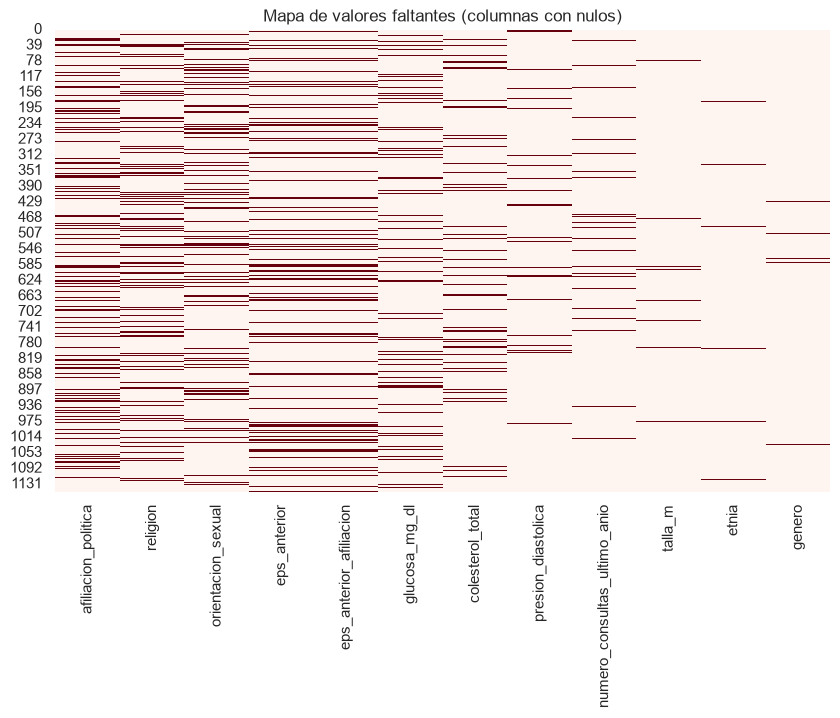

In [21]:
faltantes = df.isna().mean().sort_values(ascending=False) * 100
faltantes = faltantes[faltantes > 0]
print("Porcentaje de valores nulos por columna:")
display(faltantes.round(2).to_frame("% nulos"))

plt.figure(figsize=(10, 6))
sns.heatmap(df[faltantes.index].isna(), cbar=False, cmap="Reds")
plt.title("Mapa de valores faltantes (columnas con nulos)")
plt.show()


 **Registre en la lista de chequeo (sección de Completitud):** qué variables clínicas clave tienen nulos y en qué porcentaje, y si ese nivel de vacíos es aceptable o requiere descartar/imputar antes del entrenamiento.


## 7. Auditoría de **Privacidad** (GDPR / Ley 1581 de 2012 – Colombia)
> ¿El dataset contiene datos personales identificables sin proteger? ¿Se respeta el principio de minimización?

Un dataset de entrenamiento **nunca** debería requerir la identidad exacta de una persona para que un modelo aprenda un patrón clínico general. La sola presencia de nombre, cédula, dirección, teléfono o correo ya constituye un dato personal identificable directo, y su uso sin seudonimización viola el principio de minimización.


In [22]:
columnas_pii_directas = ["nombre_completo", "numero_documento", "direccion_residencia",
                          "telefono_contacto", "correo_electronico"]

print("Columnas con datos personales identificables DIRECTOS encontradas:")
for c in columnas_pii_directas:
    print(f" - {c}  → ejemplo:", df[c].iloc[0])


Columnas con datos personales identificables DIRECTOS encontradas:
 - nombre_completo  → ejemplo: Elena Muñoz Valencia
 - numero_documento  → ejemplo: 2593765711
 - direccion_residencia  → ejemplo: Dg. 154 # 23A-83
Torre 1 apartamento 59
913983
Puerto Nariño, Amazonas
 - telefono_contacto  → ejemplo: (+57)3063854678
 - correo_electronico  → ejemplo: natalia58@example.com


**Propuesta de control — Seudonimización.** A continuación se muestra un ejemplo de cómo un auditor puede **proponer y demostrar técnicamente** la seudonimización de los identificadores directos (esto NO reemplaza el control real que debe implementar el equipo de datos, pero sirve para sustentar la recomendación en el informe).


In [23]:
import hashlib

def seudonimizar(valor, sal="salucompleta_2026"):
    texto = f"{sal}_{valor}"
    return hashlib.sha256(texto.encode()).hexdigest()[:16]

df_seudonimizado = df.copy()
for c in columnas_pii_directas:
    df_seudonimizado[c] = df_seudonimizado[c].astype(str).apply(seudonimizar)

df_seudonimizado[columnas_pii_directas].head()


,nombre_completo,numero_documento,direccion_residencia,telefono_contacto,correo_electronico
0,2272b378a563982f,e6bd72c283767a02,47eb87491b2ea50c,313ceeaf2fbe22d1,4dad13f547777b1f
1,14ed7f67cec9d8ec,637f3ef47a68742c,dc733b9ecc1a2a6f,c37c6ef6bbf829ec,735ce8592a09bdaf
2,a26e7fedc2bb47c1,4a71940703bd7d4f,71721cdad21b120d,89928fa95644c8cf,006ece112201ca55
3,201e3d75fd4b4f22,63cfde51c0ade78b,48e6e1469027de74,c2f9e7650504dd24,755d6e3a8cba87c2
4,38ed7effdea888d6,471f2b03efce10ae,9a481fd8c160e4c0,aa2ed19dbbca2ee6,4114d46200e9d80f


 **Registre en la lista de chequeo (sección de Privacidad):** cuáles columnas son datos personales identificables directos, cuáles son datos sensibles de categoría especial (piense también en `etnia`, `religion`, `orientacion_sexual`, y en los datos clínicos mismos, que son datos sensibles de salud bajo la Ley 1581), y qué técnica de protección propone para cada caso (seudonimización, cifrado, eliminación, agregación).


## 8. Redundancia de variables y trazabilidad / control de versiones (ISO/IEC 42001)
> Columnas redundantes generan ruido, multicolinealidad y riesgo de fuga de información (data leakage) en el modelo. Además, un dataset gobernado debe tener metadatos de versión y linaje verificables.


In [24]:
print("¿'eps_anterior' y 'eps_anterior_afiliacion' son idénticas?",
      df["eps_anterior"].equals(df["eps_anterior_afiliacion"]))

corr_redundancia = df[["edad", "peso_kg", "talla_m", "imc"]].corr(numeric_only=True).round(2)
corr_redundancia


¿'eps_anterior' y 'eps_anterior_afiliacion' son idénticas? True


,edad,peso_kg,talla_m,imc
edad,1.00,0.04,0.02,0.00
peso_kg,0.04,1.00,-0.04,0.52
talla_m,0.02,-0.04,1.00,-0.46
imc,0.00,0.52,-0.46,1.00


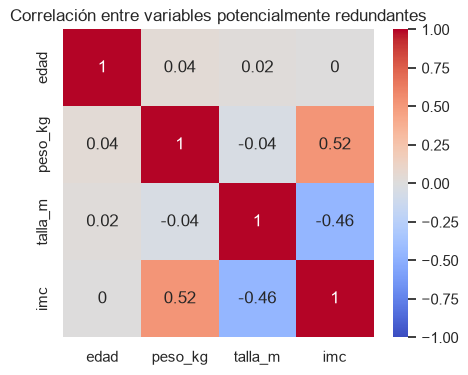

In [25]:
plt.figure(figsize=(5,4))
sns.heatmap(corr_redundancia, annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlación entre variables potencialmente redundantes")
plt.show()


 **Registre en la lista de chequeo (sección de trazabilidad/versionado):** columnas redundantes encontradas, y verifique si el archivo tiene metadatos de versión, fecha de extracción y responsable (compare con la Ficha Técnica del Word: ¿el archivo real trae esa información embebida, o solo consta en un documento aparte que nadie enlaza con el CSV?).


**Conexión con DVC:** la pregunta *"¿el archivo trae metadatos de versión, fecha y responsable?"* se contesta con evidencia en la **Sección 11**. El CSV por sí solo no los trae, pero el repositorio Git + DVC sí: hash del dato, autor y fecha del *commit*, etiqueta de versión y linaje hasta el archivo de origen.


## 9. Resumen automático de hallazgos
Esta celda consolida en un solo bloque los indicadores clave que usted debe trasladar al **Informe de Hallazgos** en Word. Úselo como apoyo, pero el juicio de riesgo (Bajo/Medio/Alto) y la recomendación de control deben ser redactados por usted como auditor.


In [26]:
posibles_irrelevantes = ["color_cabello", "marca_celular", "red_social_favorita", "equipo_futbol_favorito"]
print("="*70)
print(" RESUMEN AUTOMÁTICO DE AUDITORÍA — pacientes_salucompleta_v1.csv")
print("="*70)

print(f"\n[Volumen] Registros: {df.shape[0]}   Columnas: {df.shape[1]}")

print("\n[Pertinencia] Variables protegidas presentes:", presentes)
print("[Pertinencia] Variables irrelevantes candidatas:", posibles_irrelevantes)

print("\n[Representatividad] Distribución del target 'hospitalizado':")
print(df["hospitalizado"].value_counts(normalize=True).round(3).to_dict())
print("[Representatividad] % del grupo étnico minoritario 'Indigena':",
      round((df["etnia"] == "Indigena").mean() * 100, 2), "%")

print("\n[Integridad] Duplicados exactos (sin id):", duplicados_exactos)
print("[Integridad] Formatos distintos en 'genero':", df['genero'].nunique(dropna=True))

print("\n[Completitud] Top 5 columnas con más nulos:")
print(faltantes.head(5).round(2).to_dict())

print("\n[Privacidad] Columnas PII directas sin proteger:", columnas_pii_directas)

print("\n[Redundancia] '¿eps_anterior' duplicada exacta:",
      df["eps_anterior"].equals(df["eps_anterior_afiliacion"]))
print("="*70)

 RESUMEN AUTOMÁTICO DE AUDITORÍA — pacientes_salucompleta_v1.csv

[Volumen] Registros: 1150   Columnas: 39

[Pertinencia] Variables protegidas presentes: ['etnia', 'religion', 'orientacion_sexual', 'afiliacion_politica']
[Pertinencia] Variables irrelevantes candidatas: ['color_cabello', 'marca_celular', 'red_social_favorita', 'equipo_futbol_favorito']

[Representatividad] Distribución del target 'hospitalizado':
{'No': 0.869, 'Si': 0.131}
[Representatividad] % del grupo étnico minoritario 'Indigena': 2.17 %

[Integridad] Duplicados exactos (sin id): 12
[Integridad] Formatos distintos en 'genero': 7

[Completitud] Top 5 columnas con más nulos:
{'afiliacion_politica': 21.04, 'religion': 19.13, 'orientacion_sexual': 18.78, 'eps_anterior': 18.43, 'eps_anterior_afiliacion': 18.43}

[Privacidad] Columnas PII directas sin proteger: ['nombre_completo', 'numero_documento', 'direccion_residencia', 'telefono_contacto', 'correo_electronico']

[Redundancia] '¿eps_anterior' duplicada exacta: True


## 10. Remediación y nueva versión (v2) — registrada con DVC

> **Juego de roles:** el auditor **no corrige** el dataset de origen; devuelve los hallazgos y es el **equipo de datos** quien entrega una nueva versión. Para ver DVC en acción, aquí se simula esa entrega con un script de remediación que atiende los hallazgos de las secciones 3 a 8.

El script se registra como un **pipeline de DVC** (`dvc.yaml`): DVC anota qué archivo de entrada (v1), qué código y qué archivo de salida (v2) intervinieron, con sus hashes en `dvc.lock`. Ese es el **linaje del dato** que pide la ISO/IEC 42001.

**Qué hace el script de remediación**

- **Integridad:** elimina duplicados por `numero_documento`, estandariza `genero` y `fecha_ultima_consulta` (ISO 8601) y convierte los valores clínicamente imposibles en nulos (no los imputa: la imputación va dentro del pipeline de modelado, solo con datos de entrenamiento).
- **Privacidad:** elimina los identificadores directos (nombre, dirección, teléfono, correo y `medico_tratante`) y reemplaza el documento por un seudónimo calculado con **HMAC-SHA256** y una clave secreta (más robusto que un hash con sal fija, porque un número de documento de 10 dígitos se puede recuperar por fuerza bruta).
- **Pertinencia:** elimina las variables protegidas y las irrelevantes.
- **Redundancia:** elimina `eps_anterior_afiliacion`, `imc` y `fecha_nacimiento` (esta última, además, es un cuasi-identificador).

**Lo que el script no puede resolver:** el desbalance del target, la subrepresentación de grupos y los nulos en variables clínicas requieren recolectar más datos o decisiones de modelado. Esos hallazgos deben seguir **abiertos** en su informe.

>  Retirar las variables protegidas del entrenamiento no elimina la obligación de **medir sesgo**. En un caso real se conservarían en un archivo aparte, restringido, usado solo para evaluar equidad.

> **Buena práctica:** en proyectos reales el nombre del archivo no lleva la versión; se usa siempre el mismo nombre y la versión la llevan las etiquetas de Git (`v1.0`, `v2.0`). Aquí se usan `_v1` y `_v2` para que ambos archivos convivan y se puedan comparar en el taller.


In [27]:
%%writefile remediar_dataset.py
"""
Remediación de pacientes_salucompleta_v1.csv -> pacientes_salucompleta_v2.csv
(simula la entrega del equipo de datos de SaluCompleta tras los hallazgos de la auditoría)
"""
import hashlib
import hmac
import os

import numpy as np
import pandas as pd

ENTRADA = "pacientes_salucompleta_v1.csv"
SALIDA = "pacientes_salucompleta_v2.csv"

# Clave de seudonimización. En producción NUNCA va en el repositorio: se lee de un gestor de secretos.
CLAVE = os.environ.get("CLAVE_SEUDONIMIZACION")
if CLAVE is None:
    CLAVE = "clave-solo-para-el-taller"
    print("AVISO: se usa la clave de demostración del taller (no apta para producción).")


def seudonimo(valor):
    return hmac.new(CLAVE.encode(), str(valor).encode(), hashlib.sha256).hexdigest()[:16]


def estandarizar_fecha(serie):
    resultado = pd.Series(pd.NaT, index=serie.index)
    for formato in ["%Y-%m-%d", "%d/%m/%Y", "%d-%m-%Y", "%B %d, %Y"]:
        resultado = resultado.fillna(pd.to_datetime(serie, format=formato, errors="coerce"))
    return resultado.dt.strftime("%Y-%m-%d")


df = pd.read_csv(ENTRADA)
n_inicial = len(df)

# 1) Integridad: el mismo documento no puede corresponder a dos pacientes
df = df.drop_duplicates(subset=["numero_documento"], keep="first")

# 2) Privacidad: identificadores directos fuera; el documento se conserva solo como seudónimo
df["documento_seudonimo"] = df["numero_documento"].apply(seudonimo)
df = df.drop(columns=["numero_documento", "nombre_completo", "direccion_residencia",
                      "telefono_contacto", "correo_electronico", "medico_tratante"])

# 3) Pertinencia: variables protegidas (sin justificación técnica) e irrelevantes (ruido)
df = df.drop(columns=["etnia", "religion", "orientacion_sexual", "afiliacion_politica",
                      "color_cabello", "marca_celular", "red_social_favorita", "equipo_futbol_favorito"])

# 4) Redundancia
df = df.drop(columns=["eps_anterior_afiliacion", "imc", "fecha_nacimiento"])

# 5) Estandarización
df["genero"] = df["genero"].replace({"M": "Masculino", "masculino": "Masculino",
                                     "F": "Femenino", "femenino": "Femenino"})
df["fecha_ultima_consulta"] = estandarizar_fecha(df["fecha_ultima_consulta"])

# 6) Valores clínicamente imposibles -> nulo (no se imputan aquí)
df.loc[(df["edad"] < 0) | (df["edad"] > 110), "edad"] = np.nan
df.loc[(df["peso_kg"] <= 0) | (df["peso_kg"] > 300), "peso_kg"] = np.nan
df.loc[(df["presion_sistolica"] < 60) | (df["presion_sistolica"] > 260), "presion_sistolica"] = np.nan
df.loc[df["dias_estancia_hospitalaria"] > 90, "dias_estancia_hospitalaria"] = np.nan
for c in ["edad", "presion_sistolica", "dias_estancia_hospitalaria"]:
    df[c] = df[c].astype("Int64")

df.to_csv(SALIDA, index=False)
print(f"Remediación lista: {n_inicial} -> {len(df)} registros, {df.shape[1]} columnas -> {SALIDA}")


Writing remediar_dataset.py


**Registrar el script como etapa de un pipeline y ejecutarlo.** `dvc stage add` declara la etapa (entradas, código y salidas) en `dvc.yaml`; `dvc repro` la ejecuta y guarda en `dvc.lock` los hashes de todo lo que intervino.


In [28]:
run("dvc stage add --force -n remediar "
    "-d pacientes_salucompleta_v1.csv -d remediar_dataset.py "
    "-o pacientes_salucompleta_v2.csv python remediar_dataset.py")
run("dvc repro")

run("git add dvc.yaml dvc.lock remediar_dataset.py .gitignore")
run('git commit -m "Version v2: dataset remediado por el equipo de datos (pipeline remediar)"')
run('git tag -a v2.0-remediado -m "Version v2 tras atender los hallazgos de la auditoria"')
run("dvc push")


$ dvc stage add --force -n remediar -d pacientes_salucompleta_v1.csv -d remediar_dataset.py -o pacientes_salucompleta_v2.csv python remediar_dataset.py
Added stage 'remediar' in 'dvc.yaml'

To track the changes with git, run:

	git add dvc.yaml .gitignore

To enable auto staging, run:

	dvc config core.autostage true

$ dvc repro
'pacientes_salucompleta_v1.csv.dvc' didn't change, skipping
Running stage 'remediar':
> python remediar_dataset.py
AVISO: se usa la clave de demostración del taller (no apta para producción).
Remediación lista: 1150 -> 1130 registros, 23 columnas -> pacientes_salucompleta_v2.csv
Generating lock file 'dvc.lock'
Updating lock file 'dvc.lock'

To track the changes with git, run:

	git add dvc.lock

To enable auto staging, run:

	dvc config core.autostage true
Use `dvc push` to send your updates to remote storage.

$ git add dvc.yaml dvc.lock remediar_dataset.py .gitignore
(sin salida)

$ git commit -m "Version v2: dataset remediado por el equipo de datos (pipelin

**Ciclo de gestión de versiones (resumen).** Cada vez que el dato cambia, se repite la misma secuencia:

1. Cambiar el dato (o ejecutar el pipeline con `dvc repro`).
2. Si el archivo no es salida de un pipeline: `dvc add archivo.csv`.
3. Confirmar los punteros en Git: `git add archivo.csv.dvc dvc.lock .gitignore` y `git commit -m "motivo del cambio"`.
4. Etiquetar la versión: `git tag -a v3.0-descripcion -m "..."`.
5. Respaldar el dato: `dvc push`.

Git responde *quién, cuándo y por qué*; DVC responde *qué datos exactos*.


## 11. Auditoría de trazabilidad con DVC

> El auditor responde, **con evidencia técnica**, las preguntas de trazabilidad de la ISO/IEC 42001. Cada subsección plantea la pregunta de auditoría, el comando y qué evidencia guardar en el informe.

### 11.1 ¿Qué versiones existen, quién las creó y cuándo?


In [29]:
run("git log --decorate --date=iso")
run("git tag -n")


$ git log --decorate --date=iso
commit 111f7b3f34edda597dc7a354ea84a1cb819e0f26 (HEAD -> master, tag: v2.0-remediado)
Author: Nombre Apellido <auditor@ejemplo.com>
Date:   2026-11-04 17:50:50 -0500

    Version v2: dataset remediado por el equipo de datos (pipeline remediar)

commit 2c063af25b9b5d9800783b0e550d908025526188 (tag: v1.0-crudo)
Author: Alfredo Díaz <adiaz@unab.edu.co>
Date:   2026-11-04 17:42:28 -0500

    Linea base: dataset crudo v1 recibido del equipo de datos (sin limpiar ni validar)

$ git tag -n
v1.0-crudo      Version v1 tal como fue recibida, antes de la auditoria
v2.0-remediado  Version v2 tras atender los hallazgos de la auditoria



### 11.2 ¿Qué cambió entre v1 y v2?
`dvc diff` compara dos versiones por su hash. Para comparar el **contenido**, la API de Python de DVC (`dvc.api.open`) permite leer cualquier versión directamente desde su etiqueta, sin cambiar de rama y sin tocar el archivo actual.

> Como v1 y v2 son archivos con nombres distintos, `dvc diff` muestra v2 como *Added*. Si se mantuviera un único nombre de archivo (la buena práctica), aparecería como *Modified* con el hash anterior y el nuevo.


In [30]:
import dvc.api

run("dvc diff v1.0-crudo v2.0-remediado --show-hash")

def cargar_version(ruta, etiqueta):
    """Lee un CSV tal como estaba en una versión (etiqueta de Git)."""
    with dvc.api.open(ruta, rev=etiqueta, encoding="utf-8") as f:
        return pd.read_csv(f)

v1 = cargar_version("pacientes_salucompleta_v1.csv", "v1.0-crudo")
v2 = cargar_version("pacientes_salucompleta_v2.csv", "v2.0-remediado")

PII = ["nombre_completo", "numero_documento", "direccion_residencia", "telefono_contacto",
       "correo_electronico", "medico_tratante"]
PROTEGIDAS = ["etnia", "religion", "orientacion_sexual", "afiliacion_politica"]
IRRELEVANTES = ["color_cabello", "marca_celular", "red_social_favorita", "equipo_futbol_favorito"]
REDUNDANTES = ["eps_anterior_afiliacion", "imc", "fecha_nacimiento"]

def indicadores(d):
    col_doc = "numero_documento" if "numero_documento" in d.columns else "documento_seudonimo"
    fechas = d["fecha_ultima_consulta"].dropna().astype(str)
    imposibles = (((d["edad"] < 0) | (d["edad"] > 110)).sum()
                  + ((d["peso_kg"] <= 0) | (d["peso_kg"] > 300)).sum()
                  + ((d["presion_sistolica"] < 60) | (d["presion_sistolica"] > 260)).sum()
                  + (d["dias_estancia_hospitalaria"] > 90).sum())
    return {
        "Registros": len(d),
        "Columnas": d.shape[1],
        "Duplicados por documento": int(d.duplicated(subset=[col_doc]).sum()),
        "Identificadores directos presentes": len([c for c in PII if c in d.columns]),
        "Variables protegidas presentes": len([c for c in PROTEGIDAS if c in d.columns]),
        "Variables irrelevantes presentes": len([c for c in IRRELEVANTES if c in d.columns]),
        "Columnas redundantes presentes": len([c for c in REDUNDANTES if c in d.columns]),
        "Categorías distintas en 'genero'": d["genero"].nunique(dropna=True),
        "Fechas fuera de formato ISO 8601": int((~fechas.str.match(r"^\d{4}-\d{2}-\d{2}$")).sum()),
        "Valores clínicamente imposibles": int(imposibles),
        "% nulos en 'glucosa_mg_dl'": round(d["glucosa_mg_dl"].isna().mean() * 100, 1),
        "% de 'Si' en el target": round((d["hospitalizado"] == "Si").mean() * 100, 1),
    }

pd.DataFrame({"v1.0-crudo": pd.Series(indicadores(v1), dtype=object),
              "v2.0-remediado": pd.Series(indicadores(v2), dtype=object)})


$ dvc diff v1.0-crudo v2.0-remediado --show-hash
Added:
    437b18a2  pacientes_salucompleta_v2.csv

files summary: 1 added



,v1.0-crudo,v2.0-remediado
Registros,1150,1130
Columnas,39,23
Duplicados por documento,20,0
Identificadores directos presentes,6,0
Variables protegidas presentes,4,0
Variables irrelevantes presentes,4,0
Columnas redundantes presentes,3,0
Categorías distintas en 'genero',7,3
Fechas fuera de formato ISO 8601,838,0
Valores clínicamente imposibles,22,0


 **Registre en el informe:** qué hallazgos quedaron **cerrados** en v2 y cuáles siguen **abiertos** (fíjese en el target, la representatividad y los nulos clínicos). Un hallazgo no se da por cerrado porque el equipo de datos lo diga: se cierra cuando el auditor lo verifica sobre la nueva versión.


### 11.3 ¿De dónde viene v2? (linaje del dato)
`dvc dag` dibuja la cadena entrada → etapa → salida. `dvc.yaml` declara el pipeline y `dvc.lock` guarda el hash exacto de cada entrada, del código y de cada salida.


In [31]:
run("dvc dag")
print("---- dvc.yaml ----")
print(open("dvc.yaml").read())
print("---- dvc.lock ----")
print(open("dvc.lock").read())


$ dvc dag
+-----------------------------------+  
| pacientes_salucompleta_v1.csv.dvc |  
+-----------------------------------+  
                  *                    
                  *                    
                  *                    
            +----------+               
            | remediar |               
            +----------+

---- dvc.yaml ----
stages:
  remediar:
    cmd: python remediar_dataset.py
    deps:
    - pacientes_salucompleta_v1.csv
    - remediar_dataset.py
    outs:
    - pacientes_salucompleta_v2.csv

---- dvc.lock ----
schema: '2.0'
stages:
  remediar:
    cmd: python remediar_dataset.py
    deps:
    - path: pacientes_salucompleta_v1.csv
      hash: md5
      md5: 99b747635a2ebb187d7bd9d69e583e0f
      size: 449015
    - path: remediar_dataset.py
      hash: md5
      md5: d16847ccaeb8a3cadef392497ab7d094
      size: 2914
    outs:
    - path: pacientes_salucompleta_v2.csv
      hash: md5
      md5: 437b18a2f2cd33ecfa7943d4a72989e7
      siz

### 11.4 ¿El archivo que estoy auditando es el que quedó registrado? (verificación de integridad)
Se simula que alguien modifica a mano el archivo v1 (cambia el valor del target en un registro). `dvc status` compara el hash actual con el registrado y delata la alteración. Después se restaura el dato original desde la caché con `dvc checkout`.

> Restaurar es seguro solo porque v1 está respaldado en la caché y en el almacén remoto (`dvc push`). Sin respaldo, una modificación no registrada sería irrecuperable.


In [32]:
# 1) Simulación: alguien edita el archivo v1 por fuera del control de versiones
d = pd.read_csv(ARCHIVO_V1)
d.loc[0, "hospitalizado"] = "Si" if d.loc[0, "hospitalizado"] == "No" else "No"
d.to_csv(ARCHIVO_V1, index=False)

# 2) Verificación: DVC detecta que el hash ya no coincide con el registrado
run("dvc status")

# 3) Restauración del dato original y nueva verificación
run(f"dvc checkout {ARCHIVO_V1}.dvc --force")
run("dvc status")

# 4) ¿El respaldo en el almacén remoto está completo?
run("dvc status --cloud")


$ dvc status
remediar:
	changed deps:
		modified:           pacientes_salucompleta_v1.csv
pacientes_salucompleta_v1.csv.dvc:
	changed outs:
		modified:           pacientes_salucompleta_v1.csv

$ dvc checkout pacientes_salucompleta_v1.csv.dvc --force
M       pacientes_salucompleta_v1.csv

$ dvc status
Data and pipelines are up to date.

$ dvc status --cloud
Cache and remote 'almacen_taller' are in sync.



### 11.5 ¿Se puede reproducir v2 a partir de v1? (reproducibilidad)
`dvc repro --force` vuelve a ejecutar el pipeline desde cero. Si el hash de v2 en `dvc.lock` no cambia, el resultado es **reproducible**: el mismo dato de entrada y el mismo código producen exactamente el mismo dato de salida.


In [33]:
run("dvc repro --force")
r = run("git diff --stat -- dvc.lock", devolver=True)
if r.returncode == 0 and r.stdout.strip() == "":
    print("Reproducible: el hash de v2 es idéntico al registrado en dvc.lock.")
else:
    print("El hash cambió: revise qué entrada, código o clave de seudonimización es distinta.")


$ dvc repro --force
Verifying data sources in stage: 'pacientes_salucompleta_v1.csv.dvc'

Running stage 'remediar':
> python remediar_dataset.py
AVISO: se usa la clave de demostración del taller (no apta para producción).
Remediación lista: 1150 -> 1130 registros, 23 columnas -> pacientes_salucompleta_v2.csv

To track the changes with git, run:

	git add pacientes_salucompleta_v1.csv.dvc

To enable auto staging, run:

	dvc config core.autostage true
Use `dvc push` to send your updates to remote storage.

$ git diff --stat -- dvc.lock
(sin salida)

Reproducible: el hash de v2 es idéntico al registrado en dvc.lock.


### 11.6 Lista de verificación del auditor con DVC

| Pregunta de auditoría | Comando | Evidencia para el informe |
|---|---|---|
| ¿Qué versiones existen y quién las creó? | `git log --decorate --date=iso` · `git tag -n` | *Commit*, autor, fecha y etiqueta de cada versión |
| ¿Qué dato exacto se auditó? | Abrir `pacientes_salucompleta_v1.csv.dvc` | Hash `md5` y tamaño |
| ¿Qué cambió entre versiones? | `dvc diff v1.0-crudo v2.0-remediado --show-hash` | Archivos y hashes que cambiaron |
| ¿De dónde viene el dato? | `dvc dag` · `dvc.yaml` · `dvc.lock` | Linaje: entrada → código → salida |
| ¿El archivo actual es el registrado? | `dvc status` | "Data and pipelines are up to date" o la lista de archivos modificados |
| ¿Es reproducible? | `dvc repro --force` · `git diff dvc.lock` | Hash idéntico (sin diferencias) |
| ¿Hay respaldo recuperable? | `dvc push` · `dvc status --cloud` | Caché y almacén remoto sincronizados |
| ¿Quién puede acceder al dato? | Permisos del almacén remoto (fuera de DVC) | Política de accesos y cifrado |

 **Registre en la lista de chequeo (trazabilidad/versionado):** adjunte como anexo la salida de `git log`, `dvc diff`, `dvc dag` y `dvc status`, junto con los hashes MD5 de v1 y v2.

### 11.7 Cómo audita una persona externa, desde otro computador
El repositorio Git contiene solo código y punteros; los datos se descargan del almacén remoto **si la persona tiene permiso**. Desde una terminal (en VS Code: *Terminal → Nueva terminal*):

```
git clone <URL-del-repositorio> auditoria_salucompleta
cd auditoria_salucompleta
pip install dvc
dvc pull                    # descarga los datos desde el almacén remoto
git checkout v1.0-crudo     # viaja a la versión v1
dvc checkout                # deja en la carpeta los datos de esa versión
git checkout v2.0-remediado # viaja a la versión v2
dvc checkout
```

> En producción, el almacén remoto con datos de salud debe tener **cifrado, control de acceso por rol y registro de accesos**. DVC no reemplaza esos controles: los hereda del almacenamiento que se elija.


## 12. Cierre y siguiente paso

Con los hallazgos identificados en este notebook:

1. Complete la **Lista de Chequeo de Auditoría** en el documento Word del taller (secciones de Pertinencia, Representatividad, Integridad, Completitud, Privacidad y Trazabilidad/Versionado).
2. Redacte el **Informe de Hallazgos** con la calificación de riesgo (Bajo / Medio / Alto) para cada hallazgo.
3. Proponga, para cada hallazgo, un **control concreto y accionable** (no genérico) — por ejemplo: *"eliminar las columnas nombre_completo, numero_documento, direccion_residencia, telefono_contacto y correo_electronico antes del entrenamiento y sustituirlas por el hash SHA-256 generado en la sección 7"*, en lugar de solo decir *"mejorar la privacidad"*.
4. Adjunte la **evidencia de trazabilidad** de la sección 11 (hashes de v1 y v2, registro de Git, `dvc diff`, linaje y verificación de integridad) y indique qué hallazgos se cerraron en v2 y cuáles siguen abiertos.
5. Concluya si el dataset, **en su estado actual**, está listo para entrenar el modelo de predicción de hospitalización de SaluCompleta, o si debe devolverse al equipo de datos para su remediación.

Este es exactamente el tipo de verificación que exige la **ISO/IEC 42001** como puente entre la gobernanza de datos (DAMA-DMBOK) y la gestión responsable de sistemas de IA.
